In [1]:
### Describing subway service frequency
### Input: GTFS data. Source: https://www.transit.land/feeds/f-u2ed-wienerlinien~wlb/
### Tool: Pandas

### Step 0. Import necessary packages

In [81]:
import numpy as np
import pandas as pd
from transit_sim import Trains

%matplotlib
from IPython.display import display
import matplotlib.pyplot as plt

Using matplotlib backend: MacOSX


### Step 1. Process GTFS

In [2]:
service_id = 'T9' ### 20220808 to 20220904

trips_file = 'data/vienna_gtfs/trips.txt'
stops_file = 'data/vienna_gtfs/stops.txt'
stop_times_file = 'data/vienna_gtfs/stop_times.txt'

### create all trains from GTFS
all_trains = Trains()
all_nodes, all_links = all_trains.schedule_and_network_from_gtfs(
    stop_times_file, trips_file, stops_file, service_id)

In [3]:
all_trains.schedule_df.head()

,trip_id,time,next_time,status,location,shape_dist_traveled,location_id
0,10553.T9.21-U1-j22-1.4.H,20340.0,20370.0,stop,U1H-Reumannplatz,0.00,0.0
1,10553.T9.21-U1-j22-1.4.H,20370.0,20400.0,on_link,U1H-Reumannplatz:U1H-Keplerplatz,0.00,-1.0
2,10553.T9.21-U1-j22-1.4.H,20400.0,20430.0,stop,U1H-Keplerplatz,507.93,1.0
3,10553.T9.21-U1-j22-1.4.H,20430.0,20520.0,on_link,U1H-Keplerplatz:U1H-Südtiroler Pl. - Hbf.,0.00,-1.0
4,10553.T9.21-U1-j22-1.4.H,20520.0,20550.0,stop,U1H-Südtiroler Pl. - Hbf.,1410.85,2.0


### Step 2. Generate trajectory plot

In [128]:
fig, ax = all_trains.generate_trajectory_plot(3600*4, 3600*7, all_nodes, 'U1H')

### Step 3. Headways

In [51]:
headway_df = all_trains.schedule_df[(all_trains.schedule_df['time']>=3600*4) 
                       & (all_trains.schedule_df['time']<=3600*7)
                       & (all_trains.schedule_df['location']=='U1H-Vorgartenstraße')].copy()
headway_df = headway_df.sort_values(by='time', ascending=True)
headway_df['headway'] = headway_df['next_time'] - headway_df['next_time'].shift(1)
headway_df['headway_loc'] = (headway_df['next_time'] + headway_df['next_time'].shift(1))/2
headway_df['headway_start'] = headway_df['next_time'].shift(1)
headway_df

,trip_id,time,next_time,status,location,shape_dist_traveled,location_id,headway,headway_loc,headway_start
9902,16824.T9.21-U1-j22-1.1.H,19020.0,19050.0,stop,U1H-Vorgartenstraße,11268.46,9.0,NaN,NaN,NaN
9948,16825.T9.21-U1-j22-1.1.H,19500.0,19530.0,stop,U1H-Vorgartenstraße,11268.46,9.0,480.0,19290.0,19050.0
9994,16826.T9.21-U1-j22-1.1.H,19920.0,19950.0,stop,U1H-Vorgartenstraße,11268.46,9.0,420.0,19740.0,19530.0
10040,16827.T9.21-U1-j22-1.1.H,20400.0,20430.0,stop,U1H-Vorgartenstraße,11268.46,9.0,480.0,20190.0,19950.0
10086,16828.T9.21-U1-j22-1.1.H,20880.0,20910.0,stop,U1H-Vorgartenstraße,11268.46,9.0,480.0,20670.0,20430.0
18,10553.T9.21-U1-j22-1.4.H,21120.0,21150.0,stop,U1H-Vorgartenstraße,6693.23,9.0,240.0,21030.0,20910.0
10132,16829.T9.21-U1-j22-1.1.H,21360.0,21390.0,stop,U1H-Vorgartenstraße,11268.46,9.0,240.0,21270.0,21150.0
24376,17831.T9.21-U1-j22-1.4.H,21540.0,21570.0,stop,U1H-Vorgartenstraße,6693.23,9.0,180.0,21480.0,21390.0
10178,16830.T9.21-U1-j22-1.1.H,21780.0,21810.0,stop,U1H-Vorgartenstraße,11268.46,9.0,240.0,21690.0,21570.0
9680,16819.T9.21-U1-j22-1.2.H,22020.0,22050.0,stop,U1H-Vorgartenstraße,10168.38,9.0,240.0,21930.0,21810.0


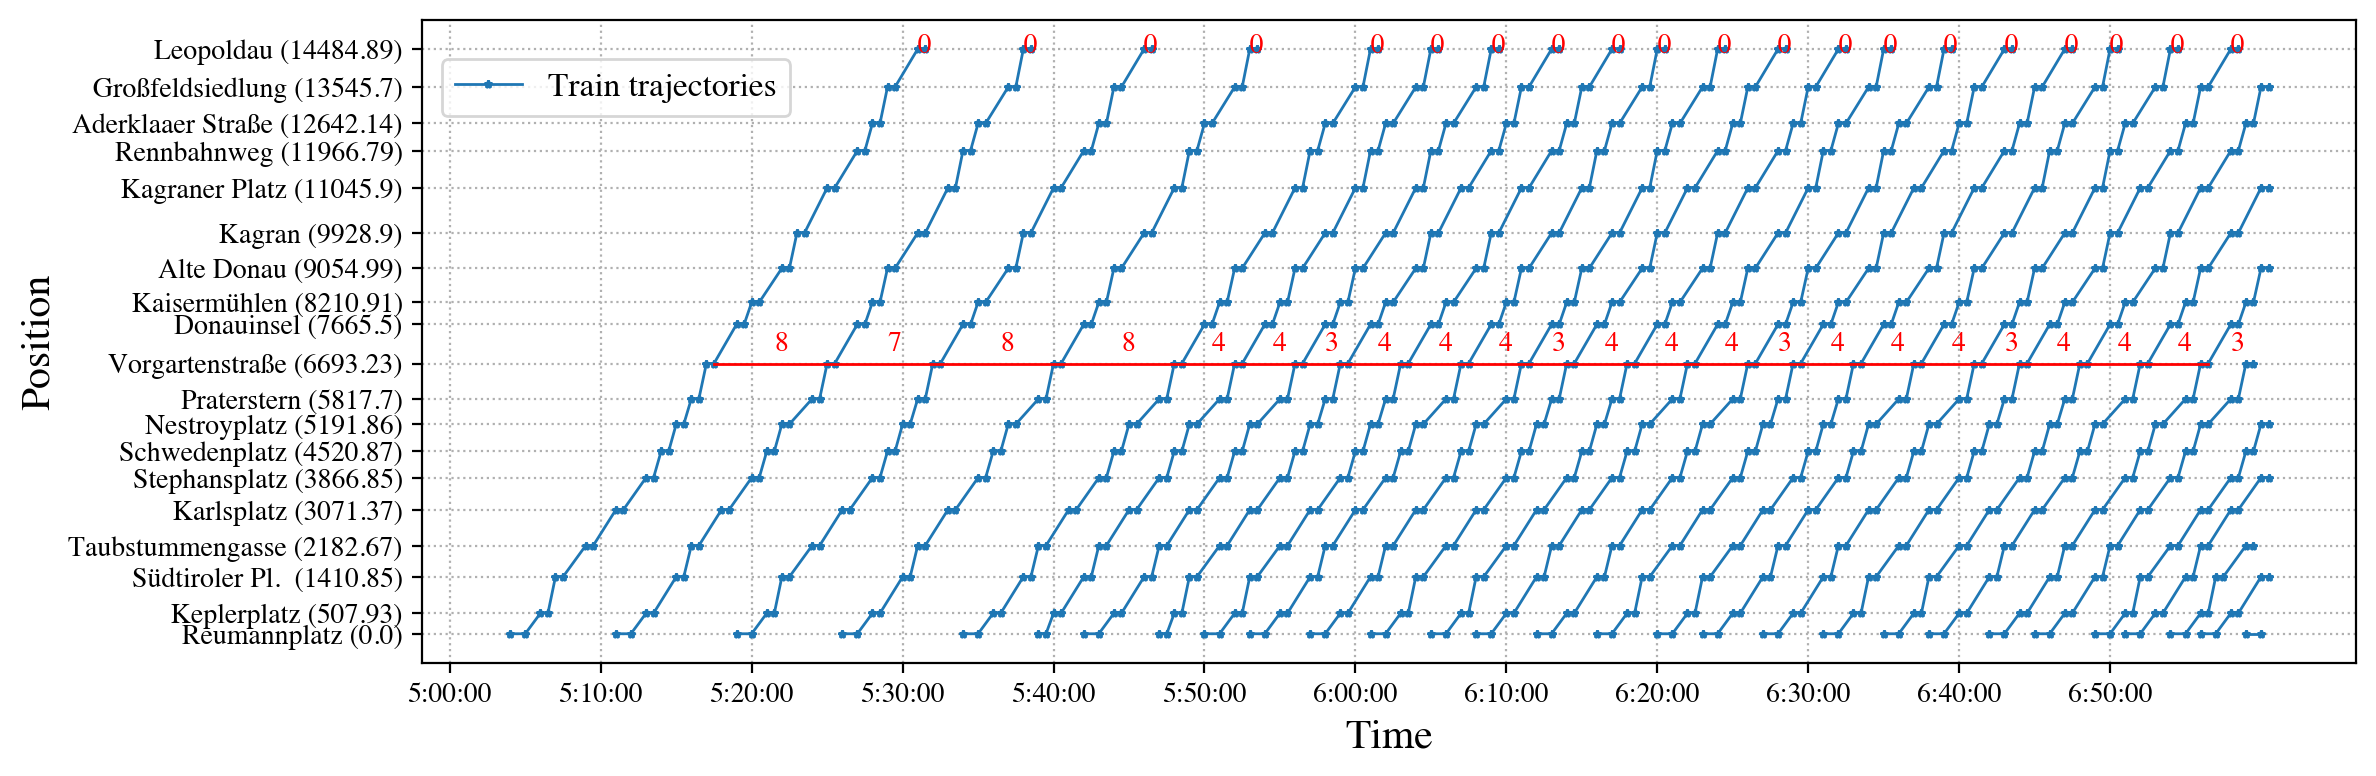

In [97]:
fig_headway, ax_headway = fig, ax
for row in headway_df.iloc[1:].itertuples():
    ax_headway.annotate(int(getattr(row, 'headway')/60), (getattr(row, 'headway_loc'), 7000), c='r')
ax_headway.plot(headway_df.iloc[1:]['headway_start'], [6693]*(headway_df.shape[0]-1), c='r', ls='-', lw=1, ms=5)
display(fig_headway)

In [76]:
(headway_df.iloc[1:]['headway']/60).describe()

count    23.000000
mean      4.434783
std       1.618812
min       3.000000
25%       4.000000
50%       4.000000
75%       4.000000
max       8.000000
Name: headway, dtype: float64

### Step 4. Speed

In [126]:
speed_df = all_trains.schedule_df[(all_trains.schedule_df['time']>=3600*4) 
                       & (all_trains.schedule_df['time']<=3600*7) 
                    & all_trains.schedule_df['location'].isin(['U1H-Reumannplatz', 'U1H-Leopoldau'])].copy()
speed_df = speed_df.groupby('trip_id').agg({'time': [np.max, np.min], 'shape_dist_traveled': [np.max, np.min]}).reset_index()
speed_df.columns = ['_'.join(col) for col in speed_df.columns]
speed_df['speed'] = (speed_df['shape_dist_traveled_amax']-speed_df['shape_dist_traveled_amin'])/(speed_df['time_amax']-speed_df['time_amin'])*3600/1000
speed_df['distance_plot_amin'] = 0
speed_df['distance_plot_amax'] = 14484.89
speed_df = speed_df.sort_values(by='time_amin', ascending=True)
speed_df.head()

,trip_id_,time_amax,time_amin,shape_dist_traveled_amax,shape_dist_traveled_amin,speed,distance_plot_amin,distance_plot_amax
11,16824.T9.21-U1-j22-1.1.H,19860.0,18240.0,19060.13,4575.23,32.188667,0,14484.89
12,16825.T9.21-U1-j22-1.1.H,20280.0,18660.0,19060.13,4575.23,32.188667,0,14484.89
13,16826.T9.21-U1-j22-1.1.H,20760.0,19140.0,19060.13,4575.23,32.188667,0,14484.89
14,16827.T9.21-U1-j22-1.1.H,21180.0,19560.0,19060.13,4575.23,32.188667,0,14484.89
15,16828.T9.21-U1-j22-1.1.H,21660.0,20040.0,19060.13,4575.23,32.188667,0,14484.89


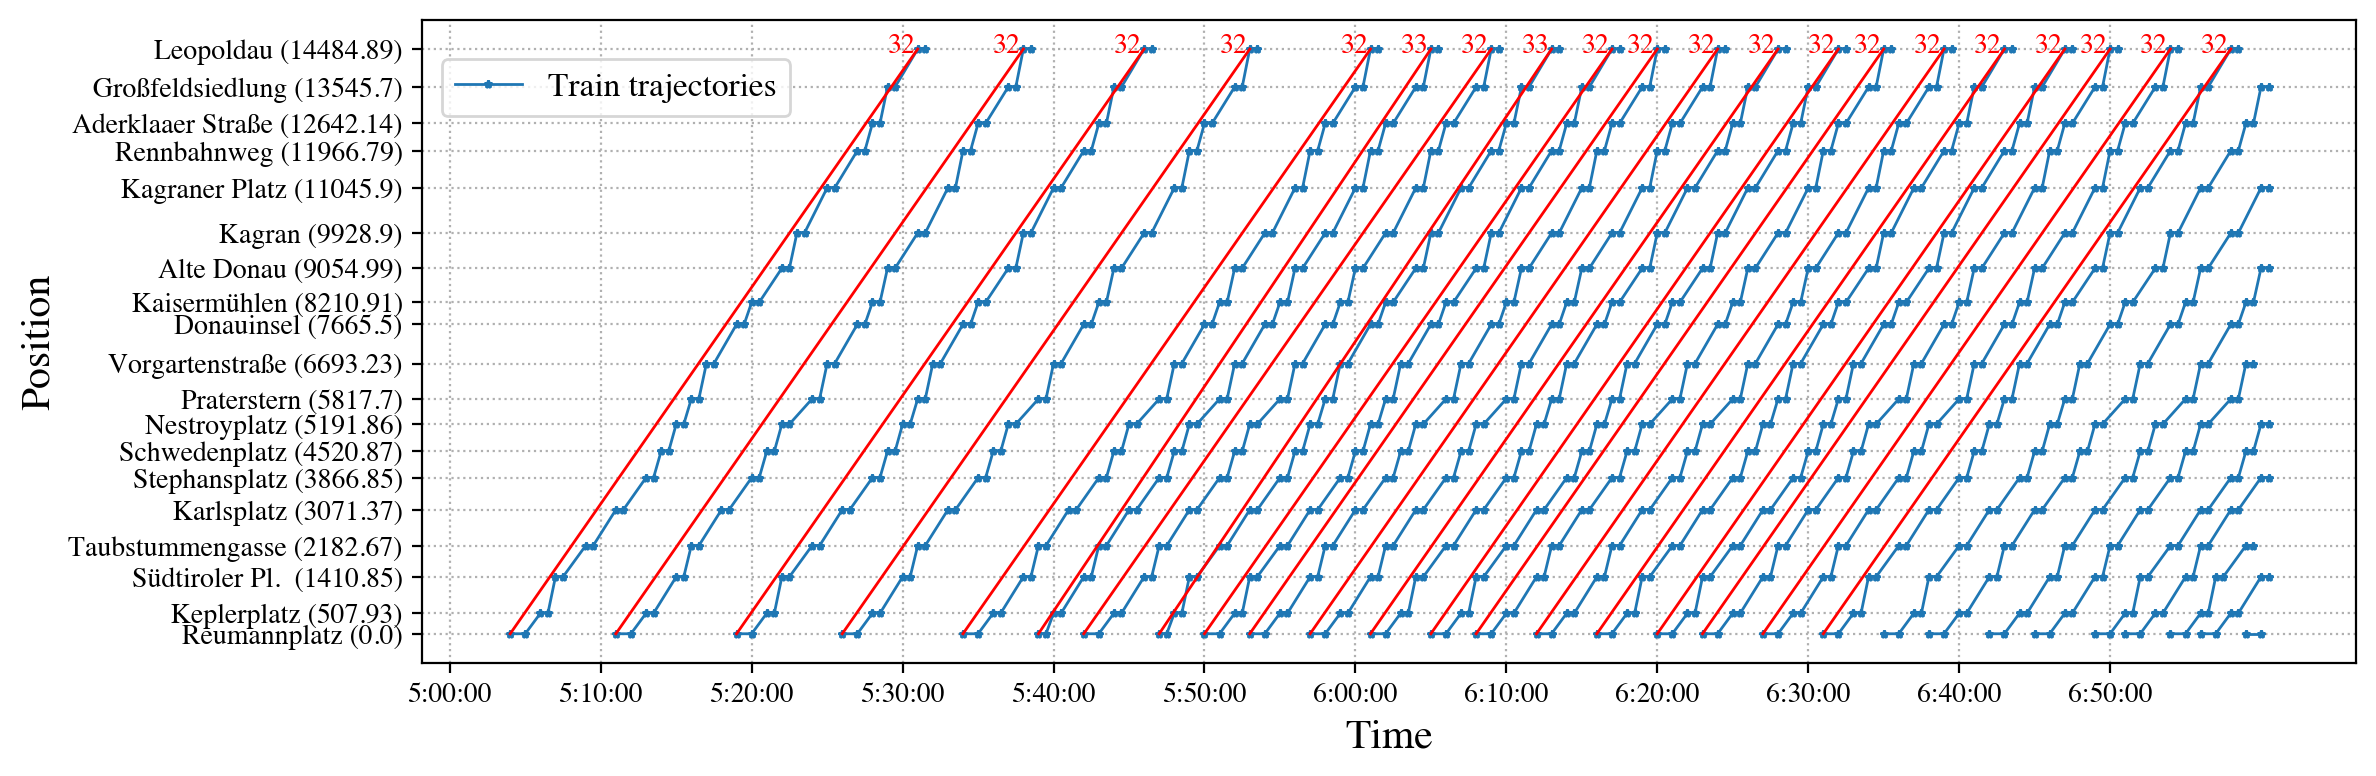

In [129]:
fig_speed, ax_speed = fig, ax
for row in speed_df.dropna().itertuples():
    ax_speed.annotate(int(getattr(row, 'speed')), (getattr(row, 'time_amax')-120, 14400), c='r')
    ax_speed.plot([getattr(row, 'time_amin'), getattr(row, 'time_amax')],
           [getattr(row, 'distance_plot_amin'), getattr(row, 'distance_plot_amax')],
           c='r', ls='-', lw=1, ms=5)
    # break
display(fig_speed)

### vehicle trajectories

In [175]:
traj_list = [(1, 50, 237), (1, 52, 282),
            (2, 50, 125), (2, 80, 272),
            (3, 80, 110), (3, 115, 240),
            (4, 130, 110), (4, 166, 278),
            (5, 180, 130), (5, 210, 280),
            (6, 225, 250), (6, 240, 275),
            (7, 270, 130), (7, 290, 200),
            (8, 285, 200), (8, 295, 275)]
traj_df = pd.DataFrame(traj_list, columns = ('vid', 'frame', 'pixel'))
traj_df['time'] = traj_df['frame']/20
traj_df['distance'] = (traj_df['pixel']-100)/200*30
traj_df

,vid,frame,pixel,time,distance
0,1,50,237,2.50,20.55
1,1,52,282,2.60,27.30
2,2,50,125,2.50,3.75
3,2,80,272,4.00,25.80
4,3,80,110,4.00,1.50
5,3,115,240,5.75,21.00
6,4,130,110,6.50,1.50
7,4,166,278,8.30,26.70
8,5,180,130,9.00,4.50
9,5,210,280,10.50,27.00


In [176]:
fig, ax = plt.subplots(figsize=(5, 3.5))
for vid, grp in traj_df.groupby('vid'):
    ax.plot(grp['time'], grp['distance'], lw=3)
ax.set_xlim([2.45, 15.05])
plt.savefig('vehicle_trajectory', transparent=True)

In [177]:
speed_df = traj_df.groupby('vid').agg({'time': [np.max, np.min], 'distance': [np.max, np.min]}).reset_index()
speed_df.columns = ['_'.join(col) for col in speed_df.columns]
speed_df['distance'] = (speed_df['distance_amax']-speed_df['distance_amin'])/1000
speed_df['duration'] = (speed_df['time_amax']-speed_df['time_amin'])/3600
speed_df['speed'] = speed_df['distance']/speed_df['duration']
speed_df

,vid_,time_amax,time_amin,distance_amax,distance_amin,distance,duration,speed
0,1,2.60,2.50,27.30,20.55,0.00675,0.000028,243.000000
1,2,4.00,2.50,25.80,3.75,0.02205,0.000417,52.920000
2,3,5.75,4.00,21.00,1.50,0.01950,0.000486,40.114286
3,4,8.30,6.50,26.70,1.50,0.02520,0.000500,50.400000
4,5,10.50,9.00,27.00,4.50,0.02250,0.000417,54.000000
5,6,12.00,11.25,26.25,22.50,0.00375,0.000208,18.000000
6,7,14.50,13.50,15.00,4.50,0.01050,0.000278,37.800000
7,8,14.75,14.25,26.25,15.00,0.01125,0.000139,81.000000


In [178]:
display(speed_df[['distance', 'duration', 'speed']])
print(np.mean(speed_df['speed']))
print(np.sum(speed_df['distance'])/np.sum(speed_df['duration']))

,distance,duration,speed
0,0.00675,0.000028,243.000000
1,0.02205,0.000417,52.920000
2,0.01950,0.000486,40.114286
3,0.02520,0.000500,50.400000
4,0.02250,0.000417,54.000000
5,0.00375,0.000208,18.000000
6,0.01050,0.000278,37.800000
7,0.01125,0.000139,81.000000


72.15428571428569
49.146067415730336
